In [28]:
import numpy as np
from numpy import cos, sin, exp, sqrt, log
import matplotlib.pyplot as plt
import pandas as pd
from scipy import integrate

## Question 3

In [7]:
print(f'{(3+4j)/(5+6j):.2f}')

0.64+0.03j


(15+24)/(25+36)+i(20-18)/(25+36)

= (39/61)+i(2/61)

= 0.64+0.03i

In [8]:
print(f'exp(2j) = {exp(2j):.2f}')
print(f'cos(3j) = {cos(3j):.2f}')

exp(2j) = -0.42+0.91j
cos(3j) = 10.07-0.00j


exp(2i) = cos(2) + isin(2)

= -0.42 + 0.91i

cos(3i) = (e^3+e^-3)/2

= (20.09 + 0.05)/2

= 10.07

In [10]:
def comp_exp(z, t):
    return exp(1j * z * t)

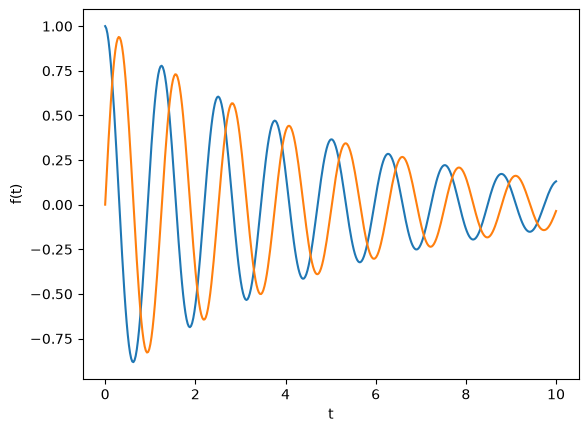

In [16]:
z = 5+0.2j
ts = np.linspace(0, 10, 400)
fs = comp_exp(z, ts)

plt.plot(ts, fs.real)
plt.plot(ts, fs.imag)
plt.xlabel('t')
plt.ylabel('f(t)')
plt.show()

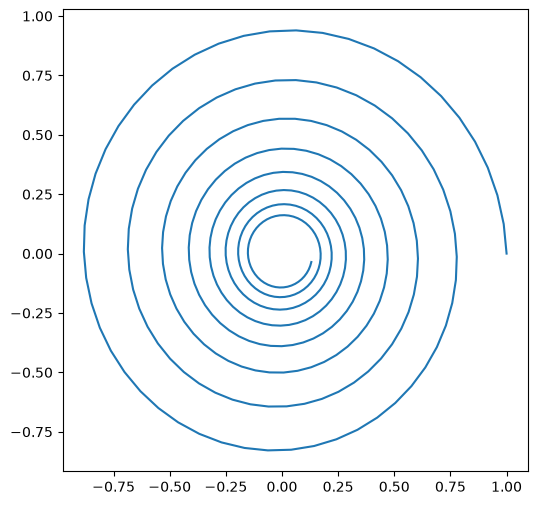

In [19]:
plt.figure(figsize=(6, 6))
plt.plot(fs.real, fs.imag)
plt.show()

## Question 4

In [21]:
a = 1
b = 5

def xsinsqr(x):
    return x * sin(x**2)

print(f'exact result: {(cos(a**2) - cos(b**2))/2}')
print(f'with scipy: {integrate.quad(xsinsqr, a, b)}')

exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)


## Question 5

In [25]:
def trap(f, a, b, nn):
    '''trapezoid-rule integration of f from a to b with nn slices'''
    h = (b - a)/nn
    wts = np.ones(nn + 1)
    wts[0] = 0.5
    wts[-1] = 0.5
    xs = np.linspace(a, b, nn + 1)
    fs = f(xs)
    return h * np.sum(fs * wts)

In [ ]:
nn = int(input('number of slices? '))

while nn < 1:
    nn = int(input('number must be greater than 1. number of slices? '))

print(f'exact result: {(cos(a**2) - cos(b**2))/2}')
print(f'with scipy: {integrate.quad(xsinsqr, a, b)}')
print(f'with trapezoid: {trap(xsinsqr, a, b, nn)}')

exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22386565059385902


In [ ]:
for nn in (10, 100, 500, 1000, 5000, 15000, 17500):
    print(f'\nN = {nn}')
    print(f'exact result: {(cos(a**2) - cos(b**2))/2}')
    print(f'with scipy: {integrate.quad(xsinsqr, a, b)}')
    print(f'with trapezoid: {trap(xsinsqr, a, b, nn)}')


N = 10
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: 0.6717514409177633

N = 100
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.21909885219554018

N = 500
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.2251968616020555

N = 1000
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22538691032238592

N = 5000
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22544771935686841

N = 15000
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22544997148229523

N = 17500
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22545004617005387


## Question 6

In [60]:
def simps(f, a, b, nn):
    if nn % 2 == 1:
        nn = nn + 1
        print(f'Number of slices odd; adjusted to be {nn}')

    h = (b - a)/nn
    xs = np.linspace(a, b, nn + 1)
    fs = f(xs)

    wts = np.ones(nn + 1)
    wts[::2] = 2 * np.ones(len(wts[::2]))
    wts[1::2] = 4 * np.ones(len(wts[1::2]))
    wts[0], wts[-1] = (1, 1)

    return h / 3 * sum(fs * wts)

In [67]:
for nn in (10, 100, 500, 1000, 5000, 15000, 17500):
    print(f'\nN = {nn}')
    print(f'exact result: {(cos(a**2) - cos(b**2))/2}')
    print(f'with scipy: {integrate.quad(xsinsqr, a, b)}')
    print(f'with trapezoid: {trap(xsinsqr, a, b, nn)}')
    print(f"with simpson's: {simps(xsinsqr, a, b, nn)}")


N = 10
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: 0.6717514409177633
with simpson's: 2.414413144691193

N = 100
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.21909885219554018
with simpson's: -0.2255205059039319

N = 500
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.2251968616020555
with simpson's: -0.22545036342899227

N = 1000
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22538691032238592
with simpson's: -0.22545025989582884

N = 5000
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.22544771935686841
with simpson's: -0.22545025300870128

N = 15000
exact result: -0.2254502529976669
with scipy: (-0.22545025299766913, 1.328919746320593e-09)
with trapezoid: -0.225449971